# Reverse commuting from Toronto, and whether GO serves it

I walk through the analysis in one notebook, in the order I did the work. Each section reads the tables written by `scripts/run_analysis.py`, so every number shown here comes from the run.

## 1. Objective and inputs

My objective is to find where Toronto residents who work in the suburbs are numerous, and where the GO and UP timetable does not get them to work in the morning and home in the evening. I cannot observe ridership. Station boardings and PRESTO are not on the open-data page, so I measured the market from the Census commuting flows and the service from the published timetable.

I first assembled the inputs and recorded each one in `data/SOURCES.md`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
from reverse.pipeline import load
table, stations, toronto, recs, meta = load()
FIG = ROOT / "reports" / "figures"

print((ROOT / "data" / "SOURCES.md").read_text())

# Sources

I assembled these files on 16 November 2026. Raw files are not in git, because several are large. `scripts/download_data.py` fetches them again. With `--seed ../go-station-scorecard/data/raw` it copies the files the GO station scorecard already holds, so the GTFS feeds and the 2021 tables are not downloaded twice.

| Input | What I use it for | Source | Licence |
| --- | --- | --- | --- |
| GO-GTFS.zip | Rail stations, Wednesday 18 Nov 2026 service, and the Saturday and Sunday spans | Metrolinx Open Data, GO Transit GTFS | Open Government Licence – Ontario – Metrolinx |
| UP-GTFS.zip | UP Express stations and service on the same dates | Metrolinx Open Data, UP Express GTFS | Open Government Licence – Ontario – Metrolinx |
| Local GTFS, 14 agencies | Bus stops within 250 m of a destination station, AM bus routes, and the scheduled train-to-bus wait | Mobility Database `latest.zip` for each feed id in `src/reverse/download.py` | Each agency's own open-data licence, named in th

## 2. The reverse market, 2016 to 2021

I first classified every flow between census subdivisions. A reverse commute is a Toronto home and a usual workplace in a subdivision with a GO or UP station. A Toronto home with a workplace in a subdivision without a station is kept apart, so it does not inflate the market. The 2021 file names the workplace without a code, so I matched names to the 2021 boundary file. I then set the 2016 flows beside 2021 as context, because work from home changed the denominator between the two counts.

In [2]:
show = toronto.copy()
show["reverse_share_of_usual_pow"] = show.reverse / show.usual_place_of_work
show.round(3)

,year,employed,worked_at_home,wfh_share,usual_place_of_work,work_in_toronto,reverse,toronto_out_no_station,inbound,reverse_share_of_usual_pow
0,2016,1361375.0,101275.0,0.074,1093360.0,884035.0,199225.0,10100.0,454465.0,0.182
1,2021,1308185.0,510065.0,0.390,648615.0,514695.0,126210.0,7710.0,237165.0,0.195


,csd_name,reverse_2016,reverse_2021,reverse_change_pct,inbound_2016,inbound_2021,inbound_change_pct,toronto_share_of_jobs_2021,wfh_share_2016,wfh_share_2021
12,Mississauga,62875.0,34845.0,-0.446,77085.0,36880.0,-0.522,0.140,0.063,0.336
4,Vaughan,44920.0,34235.0,-0.238,51490.0,27180.0,-0.472,0.280,0.075,0.344
5,Markham,38575.0,21490.0,-0.443,59085.0,29975.0,-0.493,0.284,0.083,0.386
13,Brampton,13995.0,10055.0,-0.282,47730.0,29350.0,-0.385,0.080,0.043,0.223
6,Richmond Hill,11670.0,7350.0,-0.370,29290.0,13070.0,-0.554,0.193,0.102,0.399
0,Pickering,4395.0,2925.0,-0.334,19880.0,10780.0,-0.458,0.132,0.068,0.358
15,Oakville,4625.0,2630.0,-0.431,19050.0,6515.0,-0.658,0.048,0.108,0.449
9,Newmarket,2165.0,1650.0,-0.238,7020.0,3215.0,-0.542,0.064,0.087,0.325
1,Ajax,2145.0,1600.0,-0.254,24170.0,12090.0,-0.500,0.080,0.060,0.328
8,Aurora,2125.0,1320.0,-0.379,6380.0,2760.0,-0.567,0.084,0.097,0.389


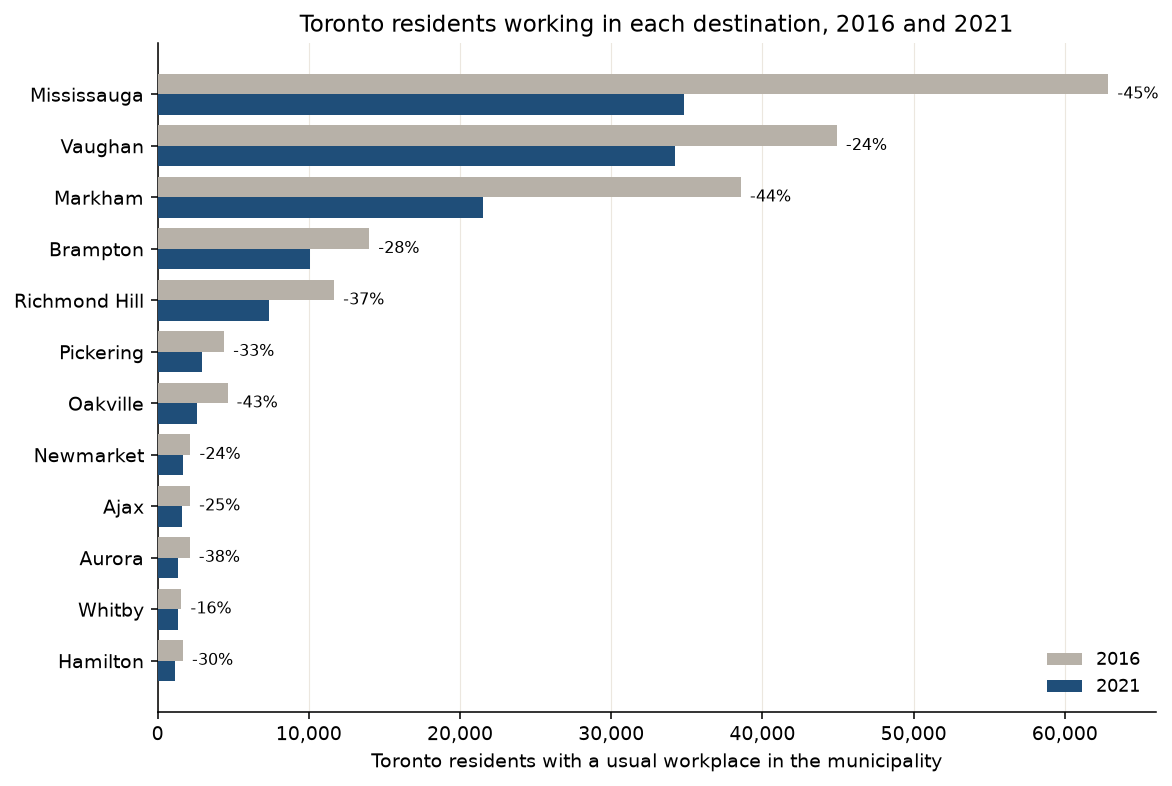

In [3]:
cols = ["csd_name", "reverse_2016", "reverse_2021", "reverse_change_pct", "inbound_2016", "inbound_2021",
        "inbound_change_pct", "toronto_share_of_jobs_2021", "wfh_share_2016", "wfh_share_2021"]
display(table.sort_values("reverse_2021", ascending=False)[cols].round(3).head(12))
display(Image(FIG / "flow_change.png"))

The 2021 Census was taken during a lockdown, so I read the 2021 counts as a floor on the in-person market and the 2016 counts as the pre-pandemic pattern. Neither is a forecast.

## 3. Counter-peak supply

I then built every one-seat ride that boards at a Toronto station and gets off at a destination station, and the reverse for the trip home. The Census places a home only at the subdivision level, so a rider can board at any Toronto station. For each destination station I measured the arrival headway from 06:30 to 09:30, the longest midday gap, the return headway toward Toronto from 15:30 to 18:30, and the span. A band with fewer than two trains gets the band length as its headway.

In [4]:
cols = ["station_name", "line_name", "csd_name", "first_arrival_clock", "am_arrivals", "am_arrival_headway_min",
        "midday_max_gap_min", "pm_return_headway_min", "last_return_clock", "weekday_span_hours", "station_supply_score"]
stations.sort_values(["line_name", "station_supply_score"], ascending=[True, False])[cols].round(1)

,station_name,line_name,csd_name,first_arrival_clock,am_arrivals,am_arrival_headway_min,midday_max_gap_min,pm_return_headway_min,last_return_clock,weekday_span_hours,station_supply_score
32,Rutherford,Barrie,Vaughan,10:23,0,180.0,67.0,180.0,21:16,10.9,27.9
43,Maple,Barrie,Vaughan,10:27,0,180.0,67.0,180.0,21:12,10.8,27.0
49,King City,Barrie,King,10:34,0,180.0,67.0,180.0,21:05,10.5,25.5
25,Aurora,Barrie,Aurora,10:44,0,180.0,67.0,180.0,20:55,10.2,24.0
10,Newmarket,Barrie,Newmarket,10:52,0,180.0,247.0,180.0,13:53,3.0,20.6
29,East Gwillimbury,Barrie,East Gwillimbury,10:56,0,180.0,330.0,180.0,13:49,2.9,9.8
33,Bradford,Barrie,Bradford West Gwillimbury,11:07,0,180.0,330.0,180.0,13:38,2.5,9.3
44,Barrie South,Barrie,Barrie,11:28,0,180.0,330.0,180.0,13:17,1.8,8.8
19,Allandale Waterfront,Barrie,Barrie,11:37,0,180.0,330.0,180.0,13:09,1.5,8.3
42,Malton,Kitchener,Mississauga,07:04,5,30.0,31.0,32.0,23:34,16.5,79.4


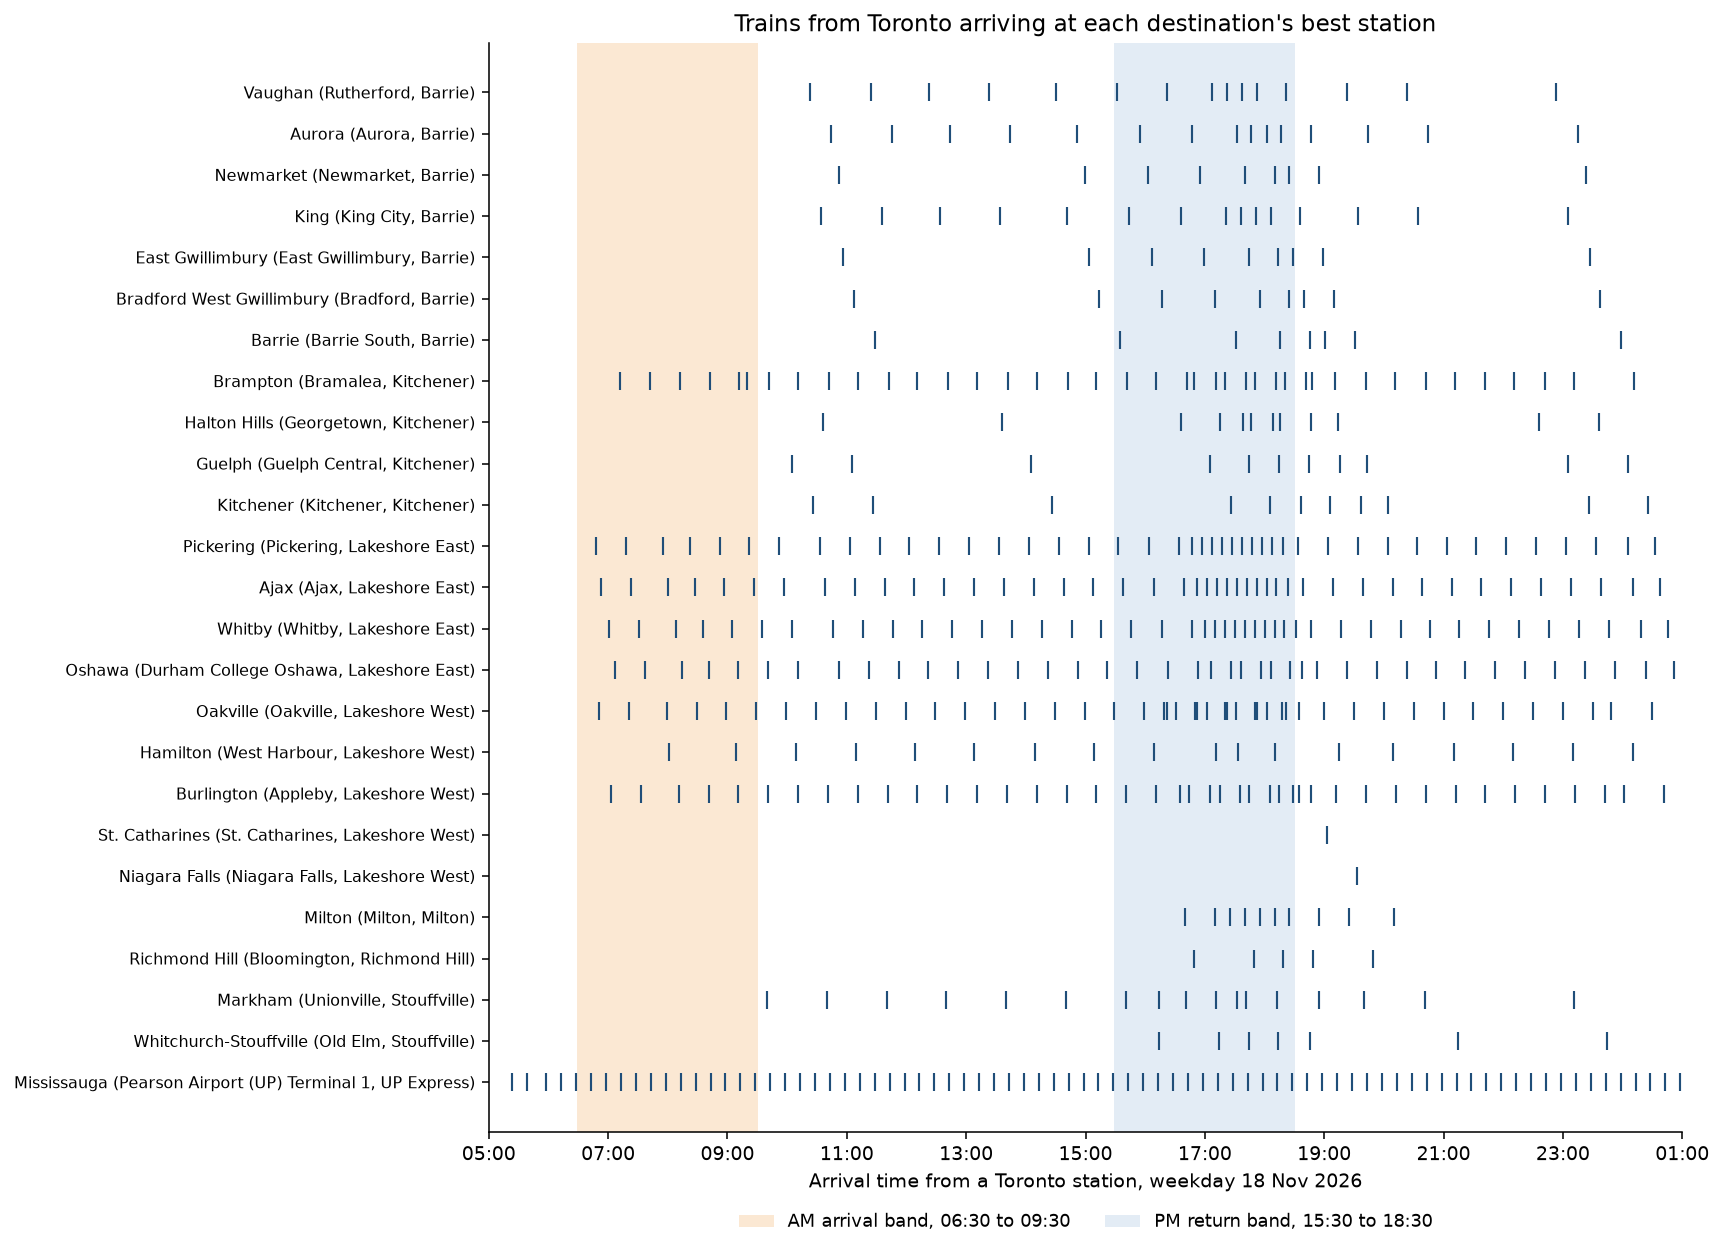

In [5]:
display(Image(FIG / "timetable_strip.png"))

The strip shows the pattern the scores summarise. Some lines run trains out of Toronto all day. Others run only toward Union in the morning and away from it in the evening, so a reverse commuter has no train in either direction when it is needed.

## 4. The last mile

A train that arrives on time still has to reach the workplace. I drew 800 m and 2 km straight-line rings around each destination station, put the 2021 jobs by census tract of work into them, and measured the share of each subdivision's jobs within 2 km of any of its stations. I then counted the local bus routes leaving each station in the AM band and the scheduled wait from a train to the next bus.

,csd_name,station_name,jobs_800m,jobs_2km,jobs_2km_share,am_bus_routes_best,train_to_bus_wait_min
11,East Gwillimbury,East Gwillimbury,570.73,4302.54,0.72,1.0,NaN
0,Pickering,Pickering,2455.24,9281.57,0.41,9.0,4.50
16,Burlington,Appleby,2533.03,10695.81,0.41,9.0,4.00
9,Newmarket,Newmarket,1954.37,10529.67,0.41,6.0,NaN
6,Richmond Hill,Bloomington,275.93,1494.15,0.39,7.0,NaN
18,Halton Hills,Georgetown,1171.38,4459.20,0.36,0.0,NaN
1,Ajax,Ajax,1106.51,7177.69,0.36,6.0,5.50
8,Aurora,Aurora,884.92,5570.20,0.35,6.0,NaN
12,Mississauga,Pearson Airport (UP) Terminal 1,2539.79,15607.91,0.35,9.0,4.50
7,Whitchurch-Stouffville,Old Elm,254.00,1009.45,0.31,2.0,NaN


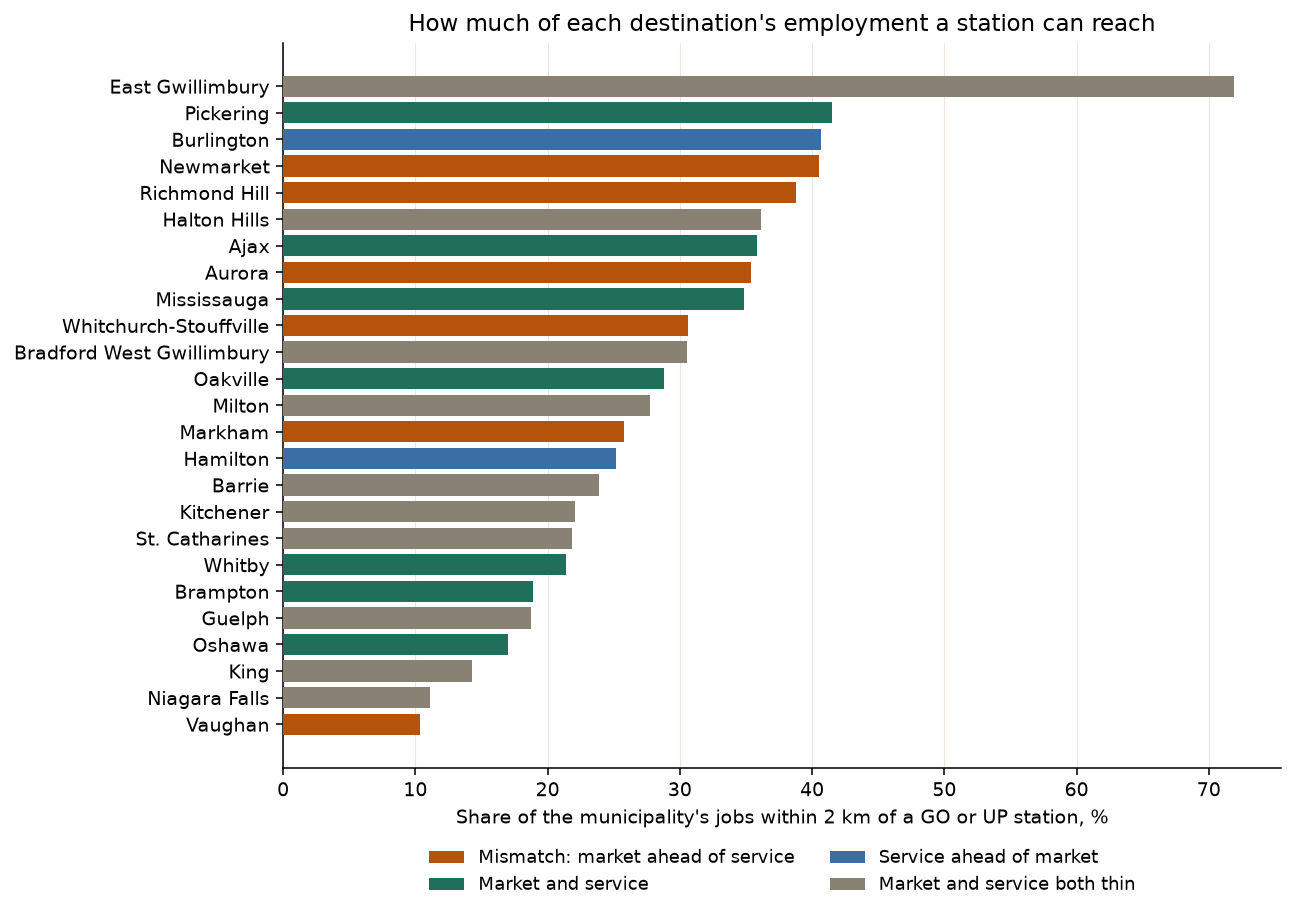

In [6]:
cols = ["csd_name", "station_name", "jobs_800m", "jobs_2km", "jobs_2km_share", "am_bus_routes_best", "train_to_bus_wait_min"]
display(table.sort_values("jobs_2km_share", ascending=False)[cols].round(2))
display(Image(FIG / "jobs_coverage.png"))

## 5. Market against service

Only after those tables were complete did I score the destinations. Every score is a percentile rank from 0 to 100, and higher is better. The market score combines the number of Toronto residents working in the municipality with their share of its jobs. The rail score ranks the best station in each municipality. A destination above the market median and below the rail median is a mismatch.

A relative rank cannot flag a gap that most destinations share. In my first run, Vaughan and Markham sat above the rail median with no train from Toronto arriving between 06:30 and 09:30. I then added a rule: a destination with no morning arrival sits on the thin-service side at any rank.

,csd_name,station_name,market_score,rail_score,last_mile_score,no_am_arrival,quadrant,near_cut,threshold_class
4,Vaughan,Rutherford,96.0,60.0,17.0,True,mismatch,False,no AM arrival
5,Markham,Unionville,96.0,64.0,51.0,True,mismatch,False,no AM arrival
12,Mississauga,Pearson Airport (UP) Terminal 1,94.0,100.0,72.0,False,market and service,False,not a mismatch
6,Richmond Hill,Bloomington,88.0,12.0,74.0,True,mismatch,False,no AM arrival
0,Pickering,Pickering,82.0,88.0,86.0,False,market and service,False,not a mismatch
13,Brampton,Bramalea,78.0,80.0,59.0,False,market and service,False,not a mismatch
1,Ajax,Ajax,70.0,84.0,65.0,False,market and service,False,not a mismatch
8,Aurora,Aurora,69.0,44.0,63.0,True,mismatch,False,no AM arrival
15,Oakville,Oakville,66.0,92.0,75.0,False,market and service,False,not a mismatch
9,Newmarket,Newmarket,66.0,36.0,71.0,True,mismatch,False,no AM arrival


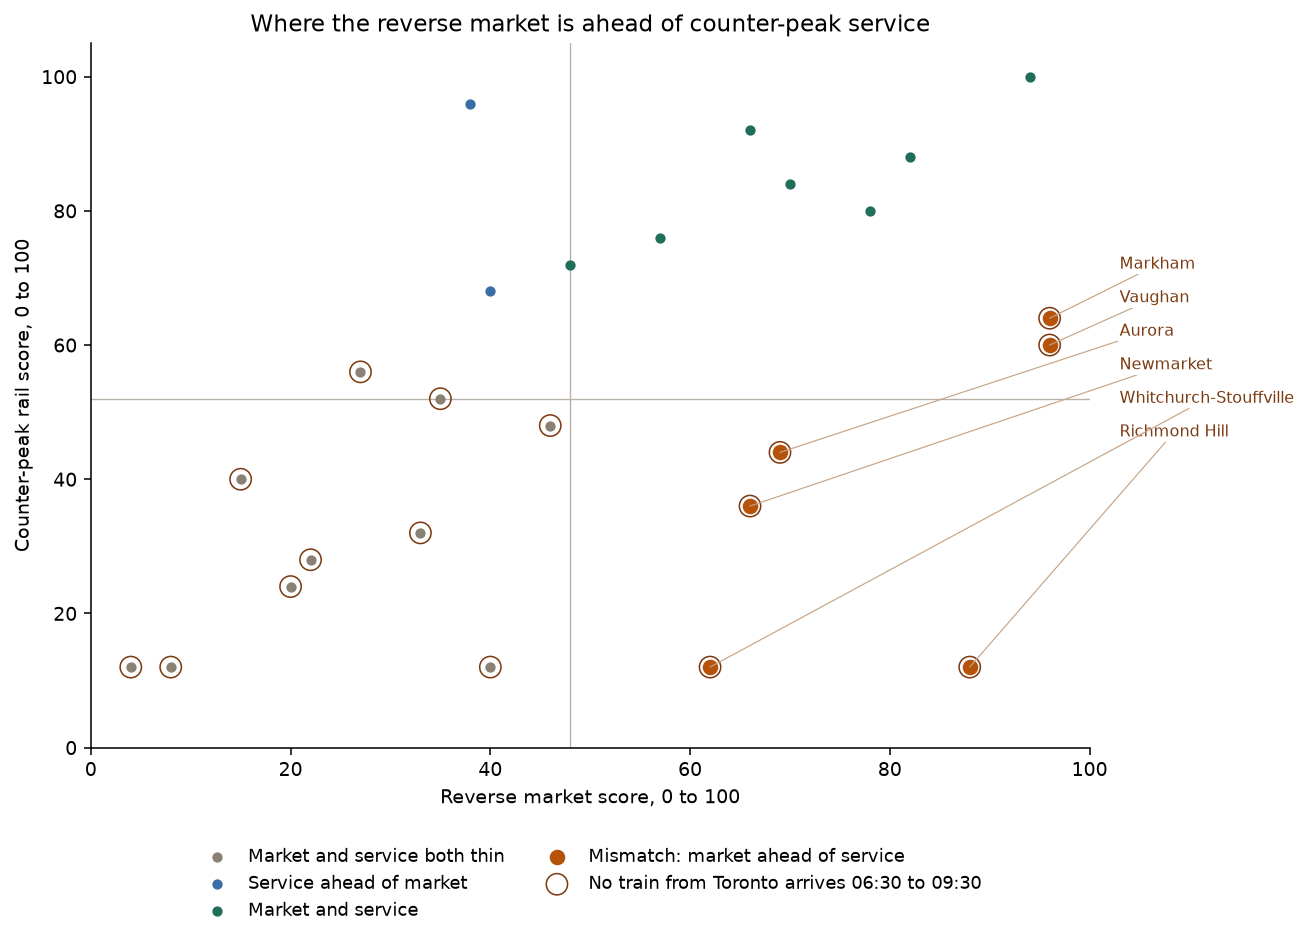

In [7]:
cols = ["csd_name", "station_name", "market_score", "rail_score", "last_mile_score", "no_am_arrival", "quadrant",
        "near_cut", "threshold_class"]
display(table.sort_values("market_score", ascending=False)[cols].round(1))
display(Image(FIG / "quadrant.png"))

In [8]:
for key in ["market_median", "rail_median", "rail_p40", "rail_p60", "mismatch_no_am", "mismatch_clear",
            "mismatch_threshold_sensitive", "mismatch_looser_only", "reference_n"]:
    print(f"{key}: {meta[key]}")

market_median: 48.0
rail_median: 52.0
rail_p40: 42.400000000000006
rail_p60: 61.599999999999994
mismatch_no_am: ['Aurora', 'Markham', 'Newmarket', 'Richmond Hill', 'Vaughan', 'Whitchurch-Stouffville']
mismatch_clear: []
mismatch_threshold_sensitive: []
mismatch_looser_only: []
reference_n: 7


## 6. Which gap to act on

For each mismatch I compared the rail and last-mile scores with the destinations that have both a strong market and strong service. When no train arrives in the morning band, the timetable is the binding gap, because nothing at the station end can be used without a train. Otherwise the larger deficit is the gap. I set the supporting evidence next to the evidence that cuts against it.

In [9]:
evidence = pd.read_csv(ROOT / "reports" / "evidence.csv")
for r in evidence.itertuples():
    print(f"{r.csd_name}: {r.primary_label}, confidence {r.confidence}")
    print(f"  Supporting: {r.supporting_evidence}")
    print(f"  Against: {r.contradictory_evidence}")
    print()

Vaughan: Counter-peak timetable, confidence high
  Supporting: No train from Toronto reaches the municipality between 06:30 and 09:30: at Rutherford, the best station, the first train from Toronto arrives at 10:23, 0 trains arrive from 06:30 to 09:30, the longest midday gap is 67 minutes, and the last train back to Toronto leaves at 21:16.
  Against: The station-to-workplace link is also behind, by 48 points: 10% of the municipality's jobs sit within 2 km of a station, the station with the most local service has 3 bus routes leaving in the AM band.

Markham: Counter-peak timetable, confidence high
  Supporting: No train from Toronto reaches the municipality between 06:30 and 09:30: at Unionville, the best station, the first train from Toronto arrives at 09:40, 0 trains arrive from 06:30 to 09:30, the longest midday gap is 60 minutes, and the last train back to Toronto leaves at 20:38.
  Against: The station-to-workplace link is also behind, by 14 points: 26% of the municipality's jobs 

In [10]:
recs[["csd_name", "best_station", "primary_gap", "confidence", "action", "owner", "kpi"]]

,csd_name,best_station,primary_gap,confidence,action,owner,kpi
0,Vaughan,Rutherford,Counter-peak timetable,high,"Add counter-peak trains from Toronto that arrive before 09:00, and a return after 17:00, before adding peak trips to...",Metrolinx service planning,"First arrival from Toronto, AM arrival headway, and last departure back to Toronto"
1,Markham,Unionville,Counter-peak timetable,high,"Add counter-peak trains from Toronto that arrive before 09:00, and a return after 17:00, before adding peak trips to...",Metrolinx service planning,"First arrival from Toronto, AM arrival headway, and last departure back to Toronto"
2,Richmond Hill,Bloomington,Counter-peak timetable,high,"Add counter-peak trains from Toronto that arrive before 09:00, and a return after 17:00, before adding peak trips to...",Metrolinx service planning,"First arrival from Toronto, AM arrival headway, and last departure back to Toronto"
3,Aurora,Aurora,Counter-peak timetable,high,"Add counter-peak trains from Toronto that arrive before 09:00, and a return after 17:00, before adding peak trips to...",Metrolinx service planning,"First arrival from Toronto, AM arrival headway, and last departure back to Toronto"
4,Newmarket,Newmarket,Counter-peak timetable,high,"Add counter-peak trains from Toronto that arrive before 09:00, and a return after 17:00, before adding peak trips to...",Metrolinx service planning,"First arrival from Toronto, AM arrival headway, and last departure back to Toronto"
5,Whitchurch-Stouffville,Old Elm,Counter-peak timetable,high,"Add counter-peak trains from Toronto that arrive before 09:00, and a return after 17:00, before adding peak trips to...",Metrolinx service planning,"First arrival from Toronto, AM arrival headway, and last departure back to Toronto"


## 7. Constraints

The 2021 flow is set beside a 2026 timetable, and the 2021 count was taken during a lockdown. Statistics Canada rounds counts at random to a multiple of 5. The flow table places homes only at the subdivision level. The last mile uses straight-line rings, and bus waits are scheduled. The TTC subway reaches Vaughan Metropolitan Centre and is outside a GO-only analysis, so a GO gap is not the same as a transit gap. The full brief is in `reports/executive_brief.md`, and the map of flows is `reports/flow_map.html`.